# 06 · Shortcut audit: why are the scores so high?

In Milestone 2, even Logistic Regression scored 99.99% on the provided columns. When a simple model is nearly perfect, it usually means **some inputs give the label away**. A model can then be "right" for reasons that have nothing to do with phishing. That's called a **shortcut**.

This notebook checks:
1. Where each column comes from.
2. How well each column separates the classes on its own.
3. How far a one-line rule gets.
4. Two hidden leaks in the dataset's URL columns.
5. How accuracy changes when whole groups of columns are removed.

**Protocol note.** Steps 2 and 3 are exploratory. To avoid peeking, the single-column AUCs use the **training split only**, and the rules are then scored on the test split. The rules themselves were first noticed while exploring the full data (notebook 01), which we state openly.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

from phishguard.data import load_clean, TARGET
from phishguard.split import get_splits
from phishguard.columns import COLUMN_GROUPS, URL_COLUMNS, STATISTIC_COLUMNS, PAGE_COLUMNS
from phishguard.evaluate import evaluate
from phishguard.experiment import run, summary_table
from phishguard.modeling import param_grid

df = load_clean()
train_idx, val_idx, test_idx = get_splits(df)
y = df[TARGET]
X = df.drop(columns=TARGET).select_dtypes("number")
cls = y.map({0: "legitimate", 1: "phishing"})

## 1. Where the columns come from (`src/phishguard/columns.py`)

| Group | Count | What it is | Can our app compute it from a typed URL? |
|---|---|---|---|
| URL | 19 | Counts and flags from the URL string | Yes |
| statistic | 3 | Scores against outside reference data, e.g. `URLSimilarityIndex` = similarity to a list of known legitimate URLs | No |
| page | 28 | Counted in the downloaded HTML (lines of code, images, forms, …) | No, it would need to download the page |

In [2]:
{group: len(cols) for group, cols in COLUMN_GROUPS.items()}

{'URL': 19, 'statistic': 3, 'page': 28}

## 2. How well does each column separate the classes on its own? (training split)

**Single-column ROC-AUC:** use the column's raw value as the score. 0.5 = useless, 1.0 = perfect separation. We report `max(AUC, 1 − AUC)`, so columns that point the "other way" count too.

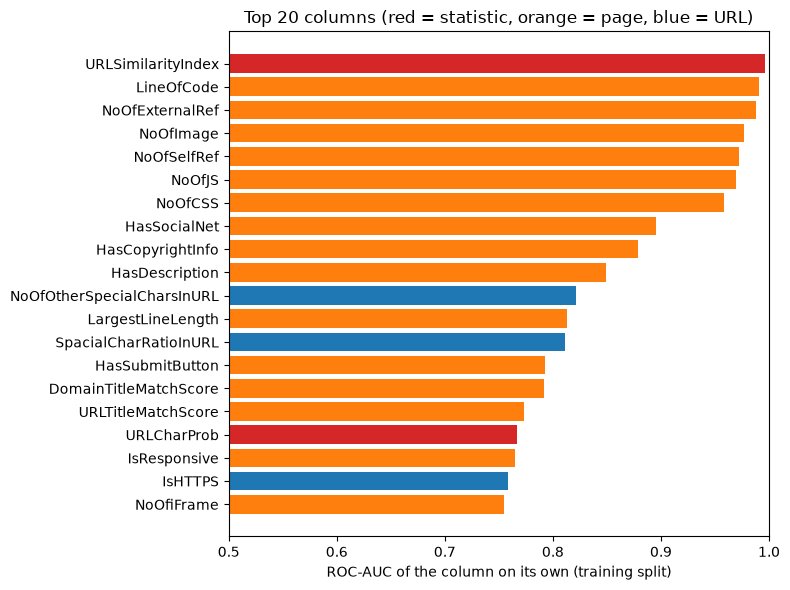

,single_column_auc,group
URLSimilarityIndex,0.9960,statistic
LineOfCode,0.9906,page
NoOfExternalRef,0.9880,page
NoOfImage,0.9772,page
NoOfSelfRef,0.9719,page
NoOfJS,0.9695,page
NoOfCSS,0.9586,page
HasSocialNet,0.8952,page
HasCopyrightInfo,0.8788,page
HasDescription,0.8493,page


In [3]:
group_of = {c: g for g, cols in COLUMN_GROUPS.items() for c in cols}
Xt, yt = X.loc[train_idx], y.loc[train_idx]
auc = pd.DataFrame({
    "single_column_auc": [max(a, 1 - a) for a in (roc_auc_score(yt, Xt[c]) for c in X.columns)],
    "group": [group_of[c] for c in X.columns],
}, index=X.columns).sort_values("single_column_auc", ascending=False)

top = auc.head(20).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top["single_column_auc"],
         color=top["group"].map({"URL": "tab:blue", "statistic": "tab:red", "page": "tab:orange"}))
plt.xlim(0.5, 1.0)
plt.xlabel("ROC-AUC of the column on its own (training split)")
plt.title("Top 20 columns (red = statistic, orange = page, blue = URL)")
plt.tight_layout()
plt.show()
auc.head(10).round(4)

- `URLSimilarityIndex` alone has AUC ≈ 0.996.
- The next six are all **page** columns, each above 0.95.
- The best **URL** column only reaches about 0.82.

## 3. One-line rules (scored on the test split, no model)

In [4]:
t = df.loc[test_idx]
no_scheme = t["URL"].str.replace(r"^https?://", "", regex=True)
rules = {
    "URLSimilarityIndex < 100  → phishing": t["URLSimilarityIndex"] < 100,
    "URL doesn't start with https://www.  → phishing": ~t["URL"].str.startswith("https://www."),
    "IsHTTPS = 0  → phishing": t["IsHTTPS"] == 0,
    "URL has a path or query  → phishing": no_scheme.str.contains(r"[/?]"),
}
pd.DataFrame({rule: evaluate(y.loc[test_idx], pred.astype(int)) for rule, pred in rules.items()}
             ).T[["accuracy", "precision", "recall", "f1"]].round(4)

,accuracy,precision,recall,f1
URLSimilarityIndex < 100 → phishing,0.9966,1.0,0.9919,0.9959
URL doesn't start with https://www. → phishing,0.9908,1.0,0.9784,0.9891
IsHTTPS = 0 → phishing,0.7943,1.0,0.5152,0.6800
URL has a path or query → phishing,0.7251,1.0,0.3522,0.5209


Two rules with no machine learning at all score about **99.7%** and **99.2%**. All four have precision 1.0: they never flag a legitimate URL, because every legitimate URL looks the same:

In [5]:
df["URL"].str.startswith("https://www.").groupby(cls).mean().rename("share starting with https://www.")

is_phishing
legitimate    1.000000
phishing      0.024085
Name: share starting with https://www., dtype: float64

**Every** legitimate URL in PhiUSIIL starts with `https://www.` and has no path: the legitimate side is a list of homepages. In the real world, phishing sites use HTTPS and `www.` too, so this rule wouldn't work there.

## 4. Two leaks hidden in the dataset's "URL" columns

### 4a. The prefix
`URLLength` minus the characters the dataset counts (letters, digits, specials, `=`, `?`, `&`) leaves the characters that were never counted, and those are mostly the prefix:

In [6]:
counted = X[["NoOfLettersInURL", "NoOfDegitsInURL", "NoOfOtherSpecialCharsInURL",
             "NoOfEqualsInURL", "NoOfQMarkInURL", "NoOfAmpersandInURL"]].sum(axis=1)
leftover = X["URLLength"] - counted
print("legitimate URLs with leftover = 12:", (leftover[y == 0] == 12).sum(), "of", (y == 0).sum())
leftover.groupby(cls).describe()[["mean", "min", "50%", "max"]]

legitimate URLs with leftover = 12: 134845 of 134849


,mean,min,50%,max
is_phishing,,,,
legitimate,12.000119,12.0,12.0,16.0
phishing,9.227477,7.0,8.0,136.0


For legitimate URLs the leftover is **12**, the length of `https://www.`, for all but 4 of 134,849 rows. For phishing it's usually 7, 8 or 11 (`http://`, `https://`, `http://www.`). A tree model can read the prefix from these counts, even without `IsHTTPS`.

### 4b. The trailing slash we removed (D3) is still inside `URLLength`
The dataset computed its columns on the *original* URLs. We removed trailing `/` in cleaning, but `URLLength` still remembers them:

In [7]:
residue = (X["URLLength"] - df["URL"].str.len()).rename("URLLength − len(cleaned URL)")
pd.crosstab(residue.clip(-2, 2), cls)

is_phishing,legitimate,phishing
URLLength − len(cleaned URL),,
-2,0,2
-1,134849,38707
0,0,37800
1,0,22842
2,0,4


For **every** legitimate URL the difference is −1; for phishing it's often 0 or +1. So "difference ≠ −1 → phishing" is a rule with 100% precision. **Consequence for Milestone 5:** the hybrid model uses only our own features, never the dataset's columns.

## 5. Removing groups of columns (XGBoost, 5 splits)

In [8]:
column_sets = {
    "all 50 columns": list(X.columns),
    "without URLSimilarityIndex": [c for c in X.columns if c != "URLSimilarityIndex"],
    "page columns only": PAGE_COLUMNS,
    "statistic columns only": STATISTIC_COLUMNS,
    "URL columns only": URL_COLUMNS,
    "URL columns without IsHTTPS": [c for c in URL_COLUMNS if c != "IsHTTPS"],
}
make_xgb = lambda: XGBClassifier(max_depth=6, n_estimators=300, learning_rate=0.1, n_jobs=-1, random_state=42)
experiments = [run(f"XGBoost: {name}", make_xgb, [{}], X[cols], y, df, features=name, group="m3_columns")
               for name, cols in column_sets.items()]
summary_table(experiments, metrics=("accuracy", "roc_auc", "pr_auc"))

,accuracy (%),roc_auc,pr_auc,"accuracy, seed 42 [95% CI]"
model,,,,
XGBoost: all 50 columns,100.00 ± 0.00,1.0000 ± 0.0000,1.0000 ± 0.0000,"100.00% [100.00%, 100.00%]"
XGBoost: without URLSimilarityIndex,99.98 ± 0.01,1.0000 ± 0.0000,1.0000 ± 0.0000,"99.98% [99.96%, 99.99%]"
XGBoost: page columns only,99.71 ± 0.08,0.9999 ± 0.0000,0.9999 ± 0.0000,"99.76% [99.70%, 99.82%]"
XGBoost: statistic columns only,99.66 ± 0.03,0.9967 ± 0.0004,0.9974 ± 0.0003,"99.66% [99.59%, 99.72%]"
XGBoost: URL columns only,99.74 ± 0.02,0.9985 ± 0.0001,0.9988 ± 0.0001,"99.77% [99.71%, 99.82%]"
XGBoost: URL columns without IsHTTPS,99.61 ± 0.06,0.9984 ± 0.0002,0.9987 ± 0.0002,"99.59% [99.29%, 99.75%]"


## What we learned
1. **Page columns alone give about 99.6%.** They describe what the crawler downloaded. Legitimate homepages are large pages; many phishing pages are small, *possibly* because they were already taken down or are simple login forms (a hypothesis we didn't test). Our app can't use these columns anyway.
2. **`URLSimilarityIndex` alone gives about 99.7%** with a one-line rule. It compares the URL with a list of legitimate sites, which is close to looking up the answer.
3. **The URL columns still give about 99.6% without `IsHTTPS`.** Their counts reveal the `https://www.` prefix, and `URLLength` even remembers the trailing slash we removed.
4. **Every legitimate URL is a bare `https://www.` homepage.** "Doesn't start with `https://www.`" alone scores about 99.2%.

So the near-perfect scores mostly measure **how PhiUSIIL was built**, not how well phishing can be detected. Notebook 07 measures what's left when the URL-level shortcuts are removed.